# 09 — Telco: Can we trust the probabilities?
**Session 6 · Objective:** Separate ranking, classification and probability quality, inspect real calibration with support and uncertainty, and test corrections without validation leakage.

A ranking orders customers. Classification adds a cutoff to choose an action. A calibrated probability of 0.3 means that approximately 30% of comparable predictions materialize across repeated customers. A good ranking does not guarantee this numerical interpretation. We cannot recover an individual's true probability from one observed outcome.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score

print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
       'NumPy': np.__version__, 'pandas': pd.__version__})
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False})
# Keep campaign euros readable without scientific notation.
pd.options.display.float_format = '{:,.4f}'.format

{'Python': '3.12.9', 'scikit-learn': '1.9.1', 'NumPy': '2.5.3', 'pandas': '3.0.6'}


## Rebuild the classroom experiment
Notebook 03 reserved a 20% holdout; notebooks 06–08 kept it closed. Session 6 introduces its evaluation **after** calibration and policy choices on validation. The classroom materials already inspected this holdout: this reproduction is not a new, untouched confirmation.

Split development again into fitting and validation. Calibration uses five shuffled stratified folds **inside fitting only**, seed 606, `ensemble=False`: out-of-fold scores train the correction and the base estimator is refitted on all fitting rows. Validation chooses the correction and cutoffs. Refit on development later, keeping those choices fixed.

The SHA-256 below matches the v4 evidence file byte for byte. Numeric parsing is row-wise; medians, scales and categories are learned inside each Pipeline. Sample sizes and bin support stay in actual customers. Campaign totals are displayed per million of the corresponding population; extrapolation creates no extra observations.

In [2]:
data_path = Path('../data/telco.csv')
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert fingerprint == '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
df = pd.read_csv(data_path)
assert df.shape == (7043, 21) and df.customerID.is_unique
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce')
X = df.drop(columns=['customerID', 'Churn'])
y = df.Churn.eq('Yes').astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
X_fit, X_valid, y_fit, y_valid = train_test_split(X_dev, y_dev, test_size=.3, stratify=y_dev, random_state=606)
assert (len(X_dev), len(X_test), len(X_fit), len(X_valid)) == (5634, 1409, 3943, 1691)
assert set(X_fit.index).isdisjoint(X_valid.index)
assert set(X_dev.index).isdisjoint(X_test.index)
assert set(X_fit.index) | set(X_valid.index) == set(X_dev.index)
for features, labels in [(X_fit, y_fit), (X_valid, y_valid), (X_test, y_test)]:
    assert features.index.equals(labels.index)
print('Dataset SHA-256:', fingerprint)
display(pd.Series({'Development n': len(X_dev), 'Holdout n': len(X_test),
                   'Fitting n': len(X_fit), 'Validation n': len(X_valid)}))

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


Development n    5634
Holdout n        1409
Fitting n        3943
Validation n     1691
dtype: int64

## Hold the algorithm fixed; change two inputs
The first model uses original inputs. The finalist retains them and adds `log1p(tenure)` and `log1p(TotalCharges)`. These row-wise logs express diminishing changes and learn no population statistics. This is **not** notebook 07's Logistic +logs versus XGBoost +polynomials comparison. `SeniorCitizen` is categorical despite its 0/1 storage.

In [3]:
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
CATEGORICAL = [c for c in X if c not in NUMERIC]
assert 'SeniorCitizen' in CATEGORICAL

def add_logs(frame):
    result = frame.copy()
    result['log_tenure'] = np.log1p(result.tenure)
    result['log_total'] = np.log1p(result.TotalCharges)
    return result

def build_model(logs=False):
    numeric = NUMERIC + (['log_tenure', 'log_total'] if logs else [])
    preprocessing = ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)])
    return Pipeline([('features', FunctionTransformer(add_logs) if logs else 'passthrough'),
                     ('preprocess', preprocessing),
                     ('model', LogisticRegression(C=1, solver='lbfgs', max_iter=2000))])

## Brier: a small calculation before the real comparison
For binary outcomes, $BS = n^{-1} \sum_i(p_i-y_i)^2$. Squaring penalizes confident errors. Brier measures overall probability quality, combining calibration and discrimination; a smaller value does not establish calibration of every bin. There is no universal acceptable Brier threshold.

In [4]:
example = pd.DataFrame({'Predicted rain probability': [.8, .2, .6], 'Rain observed': [1, 0, 0]})
example['Squared error'] = (example.iloc[:, 0] - example.iloc[:, 1])**2
display(example)
print('Illustrative Brier:', example['Squared error'].mean())

,Predicted rain probability,Rain observed,Squared error
0,0.8000,1,0.0400
1,0.2000,0,0.0400
2,0.6000,0,0.3600


Illustrative Brier: 0.14666666666666664


## Fit corrections without teaching them validation outcomes
Sigmoid (Platt) learns a smooth logistic correction of the model's decision score. Isotonic learns a monotone relationship with flat regions and interpolation between fitted levels; sparse data can make the correction unstable. All corrections below learn from fitting folds. We compare their predictions on the same separate validation customers.

In [5]:
# Independent estimators share the same fitting rows and validation customers.
models = {'original': build_model(False).fit(X_fit, y_fit),
          'raw': build_model(True).fit(X_fit, y_fit)}
cv = StratifiedKFold(5, shuffle=True, random_state=606)
for train, calibration in cv.split(X_fit, y_fit):
    assert set(train).isdisjoint(calibration)
for method in ['sigmoid', 'isotonic']:
    models[method] = CalibratedClassifierCV(
        build_model(True), method=method, cv=cv, ensemble=False).fit(X_fit, y_fit)
prob_valid = {name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()}
for probabilities in prob_valid.values():
    assert len(probabilities) == len(y_valid)
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
validation_metrics = pd.DataFrame({name: {
    'Brier': brier_score_loss(y_valid, p), 'AP': average_precision_score(y_valid, p),
    'ROC AUC': roc_auc_score(y_valid, p)} for name, p in prob_valid.items()}).T
# Fixed tie preference: raw, then sigmoid, then isotonic.
selected_method = min(['raw', 'sigmoid', 'isotonic'], key=lambda name: validation_metrics.loc[name, 'Brier'])
display(validation_metrics.round(6))
print('Validation choice:', selected_method)

,Brier,AP,ROC AUC
original,0.1318,0.6656,0.8567
raw,0.1296,0.6757,0.8615
sigmoid,0.1297,0.6757,0.8615
isotonic,0.1309,0.6610,0.8608


Validation choice: raw


The validation table is the selection evidence. The v4 classroom reference chose raw probabilities: neither correction improved validation Brier. A negative result is useful; do not deploy calibration just because it is available. AP and AUC describe ranking, while Brier assesses the numerical probabilities. Which metric corresponds to your intended use?

In [6]:
def bin_table(labels, probabilities):
    labels, probabilities = np.asarray(labels), np.asarray(probabilities)
    # Eight fixed bins of width .125; the last includes probability 1.
    membership = np.minimum(np.searchsorted(np.linspace(0, 1, 9), probabilities, side='right') - 1, 7)
    rows = []
    for b in range(8):
        mask = membership == b
        n = int(mask.sum())
        events = int(labels[mask].sum())
        rate = events / n if n else np.nan
        # Wilson uncertainty for a binomial rate, conditional on these fixed bins.
        z = 1.96
        denominator = 1 + z*z/n if n else np.nan
        center = (rate + z*z/(2*n))/denominator if n else np.nan
        half = z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n))/denominator if n else np.nan
        rows.append({'Bin left': b/8, 'Bin right': (b+1)/8, 'Customers': n,
                     'Churns': events, 'Mean predicted': probabilities[mask].mean() if n else np.nan,
                     'Observed rate': rate, 'Wilson low': max(0, center-half) if n else np.nan,
                     'Wilson high': min(1, center+half) if n else np.nan})
    result = pd.DataFrame(rows)
    assert result.Customers.sum() == len(labels) and result.Churns.sum() == labels.sum()
    return result

def reliability(ax, table, label):
    populated = table[table.Customers > 0]
    ax.errorbar(populated['Mean predicted'], populated['Observed rate'],
                yerr=[populated['Observed rate']-populated['Wilson low'],
                      populated['Wilson high']-populated['Observed rate']],
                marker='o', capsize=3, label=label)
    ax.plot([0, 1], [0, 1], '--', color='grey')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted churn probability',
           ylabel='Observed churn frequency')
    ax.legend()

## Where do probability and frequency disagree?
The horizontal coordinate is the average forecast in a bin; the vertical coordinate is observed churn. Above the diagonal means underprediction; below means overprediction. Wilson 95% intervals describe outcome-rate uncertainty within fixed bins, excluding retraining and bin-selection uncertainty. Inspect actual support before interpreting a gap.

,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,707,30,0.0470,0.0424,0.0299,0.0599
1,0.1250,0.2500,275,48,0.1838,0.1745,0.1343,0.2238
2,0.2500,0.3750,216,67,0.3063,0.3102,0.2523,0.3747
3,0.3750,0.5000,151,67,0.4378,0.4437,0.3668,0.5234
4,0.5000,0.6250,137,90,0.5615,0.6569,0.5741,0.7312
5,0.6250,0.7500,101,61,0.6889,0.6040,0.5065,0.6938
6,0.7500,0.8750,90,74,0.8036,0.8222,0.7306,0.8875
7,0.8750,1.0000,14,12,0.9076,0.8571,0.6006,0.9599


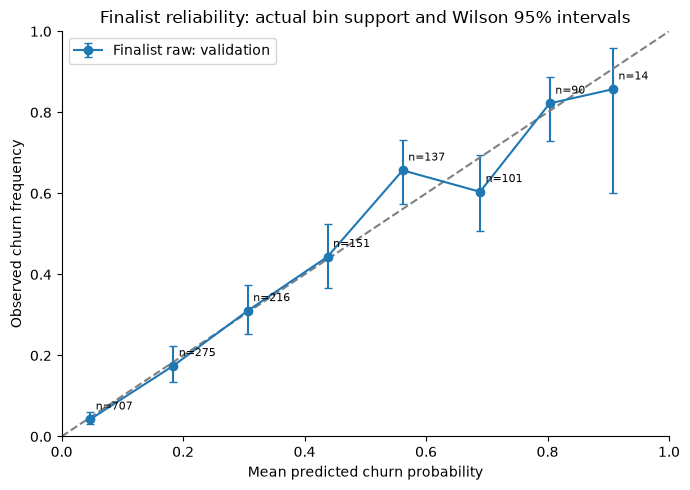

In [7]:
raw_bins = bin_table(y_valid, prob_valid['raw'])
display(raw_bins.round(4))
fig, ax = plt.subplots(figsize=(7, 5))
reliability(ax, raw_bins, 'Finalist raw: validation')
for row in raw_bins.itertuples():
    if row.Customers:
        ax.annotate(f'n={row.Customers}', (row._5, row._6), xytext=(4, 7), textcoords='offset points', fontsize=8)
ax.set_title('Finalist reliability: actual bin support and Wilson 95% intervals')
plt.tight_layout()
plt.show()

## Learned mapping is not observed reliability
Here x is an original probability and y is its fitted correction, both on [0, 1]. With `ensemble=False`, both calibrators use a base estimator refitted on the same fitting data. Logistic Regression's decision score is log-odds, so convert the probability grid back to log-odds before passing it to each fitted calibrator. These are learned transformations, not outcome frequencies on new customers.

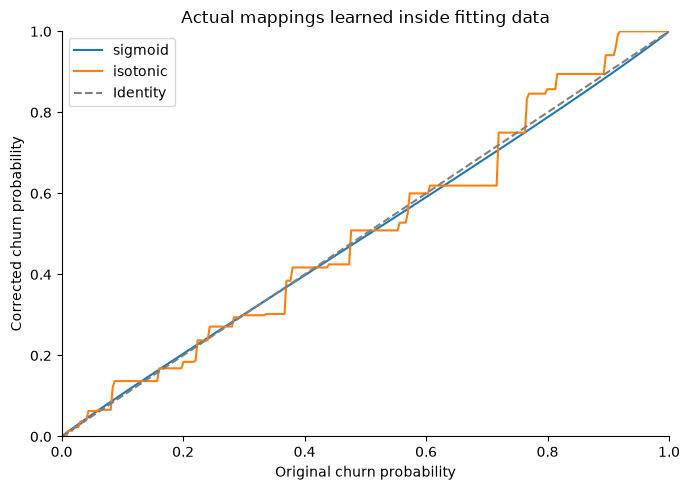

In [8]:
grid = np.linspace(.001, .999, 301)
scores = np.log(grid / (1-grid))
fig, ax = plt.subplots(figsize=(7, 5))
for method in ['sigmoid', 'isotonic']:
    calibrated = models[method].calibrated_classifiers_[0]
    assert np.allclose(calibrated.estimator.predict_proba(X_valid)[:, 1], prob_valid['raw'])
    correction = calibrated.calibrators[0]
    ax.plot(grid, correction.predict(scores), label=method)
ax.plot([0, 1], [0, 1], '--', color='grey', label='Identity')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Original churn probability',
       ylabel='Corrected churn probability', title='Actual mappings learned inside fitting data')
ax.legend()
plt.tight_layout()
plt.show()

raw - actual validation bin support


,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,707,30,0.0470,0.0424,0.0299,0.0599
1,0.1250,0.2500,275,48,0.1838,0.1745,0.1343,0.2238
2,0.2500,0.3750,216,67,0.3063,0.3102,0.2523,0.3747
3,0.3750,0.5000,151,67,0.4378,0.4437,0.3668,0.5234
4,0.5000,0.6250,137,90,0.5615,0.6569,0.5741,0.7312
5,0.6250,0.7500,101,61,0.6889,0.6040,0.5065,0.6938
6,0.7500,0.8750,90,74,0.8036,0.8222,0.7306,0.8875
7,0.8750,1.0000,14,12,0.9076,0.8571,0.6006,0.9599


sigmoid - actual validation bin support


,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,694,26,0.0490,0.0375,0.0257,0.0543
1,0.1250,0.2500,284,51,0.1845,0.1796,0.1393,0.2284
2,0.2500,0.3750,222,68,0.3069,0.3063,0.2494,0.3698
3,0.3750,0.5000,154,71,0.4368,0.4610,0.3842,0.5398
4,0.5000,0.6250,140,91,0.5592,0.6500,0.5679,0.7240
5,0.6250,0.7500,109,69,0.6916,0.6330,0.5395,0.7175
6,0.7500,0.8750,75,62,0.8027,0.8267,0.7257,0.8958
7,0.8750,1.0000,13,11,0.9006,0.8462,0.5776,0.9567


isotonic - actual validation bin support


,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,606,16,0.0388,0.0264,0.0163,0.0425
1,0.1250,0.2500,361,58,0.1624,0.1607,0.1264,0.2021
2,0.2500,0.3750,225,69,0.2887,0.3067,0.2501,0.3697
3,0.3750,0.5000,131,52,0.4176,0.3969,0.3172,0.4825
4,0.5000,0.6250,236,153,0.5667,0.6483,0.5855,0.7064
5,0.6250,0.7500,1,0,0.6396,0.0000,0.0000,0.7935
6,0.7500,0.8750,82,59,0.7948,0.7195,0.6141,0.8052
7,0.8750,1.0000,49,42,0.9063,0.8571,0.7333,0.9290


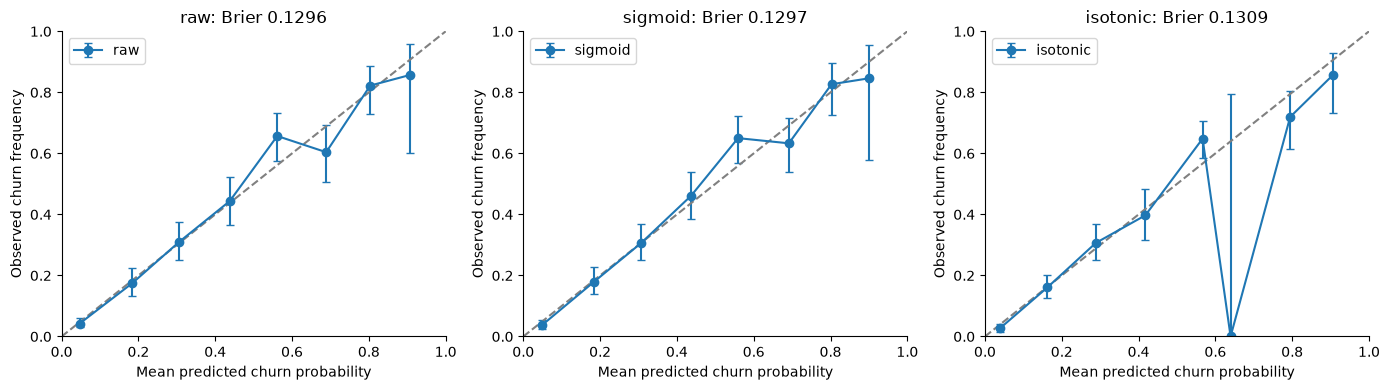

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, method in zip(axes, ['raw', 'sigmoid', 'isotonic']):
    table = bin_table(y_valid, prob_valid[method])
    print(method, '- actual validation bin support')
    display(table.round(4))
    reliability(ax, table, method)
    ax.set_title(f"{method}: Brier {validation_metrics.loc[method, 'Brier']:.4f}")
plt.tight_layout()
plt.show()

**Observation:** Compare the calculated validation Brier values and intervals, rather than assuming a correction helps. Isotonic's mapping can have plateaus, but jumps in an observed reliability diagram can also arise from sparse bins for any model. These plots answer different questions.

**Hypothesis:** More calibration data might stabilize a correction. **Uncertainty:** validation selection itself can be optimistic. **Decision:** retain the validation-selected method, then refit it on development in notebook 11 without selecting again on holdout. **Question:** Would a slight global Brier gain justify a correction if a business-critical group worsened?

We have used validation only here; the next notebook checks contract groups, and notebook 11 evaluates fixed policies on the previously inspected classroom holdout. Session 7 will ask why predictions differ; Session 8 will monitor probability quality as customers and inputs change.

### Read the executed evidence
Raw finalist validation Brier is 0.129578, compared with 0.129700 for sigmoid and 0.130867 for isotonic. The first original-input model has Brier 0.131801 on the same customers. Neither correction improves this validation comparison, so we retain raw finalist probabilities. These are global scores, not certificates of calibration in each bin.

For raw risk in [0.5, 0.625), 90 of 137 customers churn: observed frequency is about 65.7%, versus 56.1% mean predicted risk. At [0.875, 1], only 14 customers support the estimate; the Wilson interval is correspondingly wide. The calibrated diagrams' support tables help distinguish an unstable observed frequency from the shape of the learned mapping. What additional data would make a high-risk calibration conclusion more convincing?